# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722 F1 macro: 0.971
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



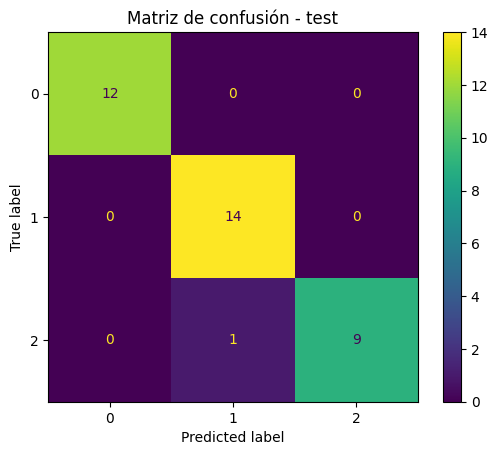

In [4]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
print("Accuracy test:", round(accuracy,4), "F1 macro:",round(f1_macro,4))
print(classification_report(y_test,y_pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred); plt.title("Matriz de confusión - test");plt.show()

**Análisis:** Comparo el accuracy de test con el promedio obtenido en validación cruzada. Una diferencia pequeña es esperable porque el test tiene pocos registros. Para identificar las clases confundidas, reviso las celdas fuera de la diagonal en la matriz. No se puede concluir que no existe sobreajuste solo porque el resultado sea bueno; por eso también revisamos los resultados de CV.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Comprueba las columnas y devuelve predicciones y probabilidades."""
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas: {missing}")
    ordered = records.loc[:, feature_columns]
    result = pd.DataFrame({"prediction": model.predict(ordered)}, index=records.index)
    if hasattr(model, "predict_proba"):
        for i, label in enumerate(model.classes_):
            result[f"prob_class_{label}"] = model.predict_proba(ordered)[:, i]
    return result

## 4. Predicción por lotes

In [6]:
new_records = X_test.iloc[:5].copy()
batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv",index=False)
print(batch_predictions)

   prediction  prob_class_0  prob_class_1  prob_class_2
0           0      0.999671      0.000307      0.000023
1           1      0.007051      0.540423      0.452526
2           0      0.992000      0.007664      0.000336
3           1      0.289967      0.707467      0.002565
4           1      0.033032      0.962313      0.004655


## 5. Reporte final

In [7]:
metrics = {"model":training_metadata["champion_name"],"cv_accuracy":training_metadata["cv_accuracy"],"accuracy":float(accuracy),"f1_macro":float(f1_macro)}
(REPORTS_DIR / "test_metrics.json").write_text(json.dumps(metrics,indent=2),encoding="utf-8")
print(metrics)

{'model': 'LogisticRegression', 'cv_accuracy': 0.9790640394088669, 'accuracy': 0.9722222222222222, 'f1_macro': 0.9709618874773139}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

Los valores exactos están guardados en `reports/test_metrics.json` y aparecen en la ejecución de arriba. El modelo campeón se seleccionó con validación cruzada, y el conjunto de test solo se utilizó para la evaluación final. La principal limitación es que tenemos pocos ejemplos, así que las métricas pueden cambiar si usamos otra muestra.

## Checklist
- [x] Evalué el campeón sin reentrenarlo.
- [x] No ajusté parámetros con test.
- [x] Implementé inferencia por lotes y guardé métricas.